# Area summaries {#sec-areas}

:::{.aside}
Our setup for this R session is: 

In [17]:
#| warnings: false
#| message: false
library(sf)
library(ecoSynthesis)
library(dplyr)
library(units)
library(ggplot2)

In [18]:
here::i_am("synthesis/EFG-map.qmd")
output_dir <- here::here("output-XREFs")
source(here::here("inc/setup.R"))
load(here::here(output_dir, "lookup-tables.rda"))
load(here::here(output_dir, "memb-summaries.rda"))

here() starts at /Users/z3529065/proyectos/EIW/TASVEG-XREF



:::

## Summarising areas

We read the spatial data from the TASVEG dataset using `read_sf` from the `sf` package.

We then use the `st_area` to calculate the spatial extent of each spatial feature.For the next calculation we don't need to keep the spatial information, so we use  but we drop the geometry column to speed up other calculations.  

In [19]:
TASVEG_xy <- read_sf(here::here("gisdata","TASVEG_5_0.shp")) |>
    select(VEG_GROUP, VEGCODE, VEGCODE_D)
TASVEG_areas <- TASVEG_xy |> 
    mutate(area = st_area(geometry)) |> 
    st_drop_geometry()

We have four different membership summary tables created in @sec-synthesis. Each one of these approaches will lead to different interpretation of spatial data linked to the source concepts and their mapping units.

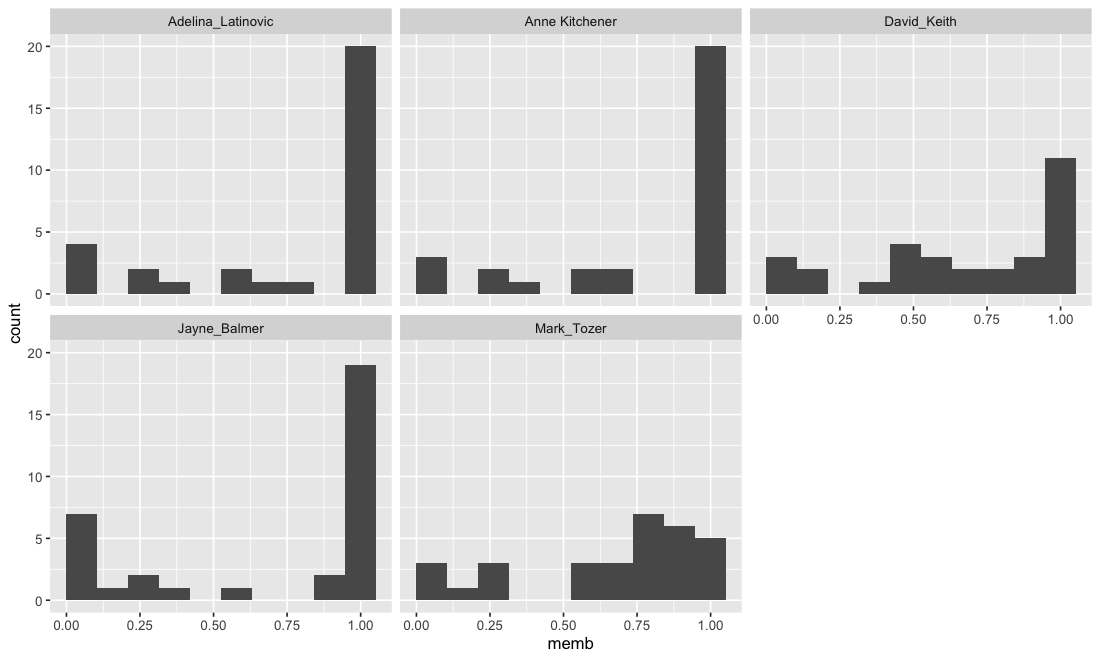

In [36]:
TASVEG_revised |>
    filter(EFG == "T2.5") |>
    ggplot() +
    geom_histogram(aes(x=memb), bins=10) +
    facet_wrap(~expert)

### Keep all records + weighted area estimates

In [27]:
EFG_memb_exp_areas <- TASVEG_areas |>
    left_join(TASVEG_revised, by = "VEGCODE", relationship = "many-to-many") |> 
    mutate(EFG = coalesce(EFG,"!XREF")) |>
    summarise(
        nr_VEGCODE = n_distinct(VEGCODE),
        mean_memb = mean(memb),
        area_total = set_units(sum(area),'km2') ,
        area_weighted = set_units(sum(area * memb),'km2') ,
          .by=c(expert, EFG)) |>
    filter(!is.na(area_total))

In [28]:
EFG_memb_exp_areas |>
  filter(EFG == "T2.5")

expert,EFG,nr_VEGCODE,mean_memb,area_total,area_weighted
<chr>,<chr>,<int>,<dbl>,<[km^2]>,<[km^2]>
Anne Kitchener,T2.5,30,0.8183604,15195.04 [km^2],13205.87 [km^2]
Adelina_Latinovic,T2.5,31,0.8189348,15221.36 [km^2],13238.79 [km^2]
David_Keith,T2.5,31,0.6168920,16794.75 [km^2],11057.29 [km^2]
Jayne_Balmer,T2.5,33,0.7683668,18477.23 [km^2],12937.90 [km^2]
Mark_Tozer,T2.5,31,0.6574286,18621.15 [km^2],11968.37 [km^2]


In [29]:
EFG_mode_exp_areas <- TASVEG_areas |>
    left_join(TASVEG_max_by_expert, by = "VEGCODE", relationship = "many-to-many") |> 
    mutate(EFG = coalesce(EFG,"!XREF")) |>
    summarise(
        nr_VEGCODE = n_distinct(VEGCODE),
        mean_memb = mean(memb),
        area_total = set_units(sum(area),'km2') ,
        area_weighted = set_units(sum(area * memb),'km2') ,
          .by=c(expert, EFG)) |>
    filter(!is.na(area_total))
    

In [30]:
EFG_mode_exp_areas |>
  filter(EFG == "T2.5")

expert,EFG,nr_VEGCODE,mean_memb,area_total,area_weighted
<chr>,<chr>,<int>,<dbl>,<[km^2]>,<[km^2]>
Anne Kitchener,T2.5,24,0.9692852,12729.99 [km^2],12381.12 [km^2]
Adelina_Latinovic,T2.5,24,0.9722410,12729.99 [km^2],12411.41 [km^2]
David_Keith,T2.5,26,0.7834967,13066.20 [km^2],10660.26 [km^2]
Jayne_Balmer,T2.5,22,0.9747669,12400.03 [km^2],12149.21 [km^2]
Mark_Tozer,T2.5,24,0.8511534,12808.83 [km^2],11287.21 [km^2]


In [14]:
EFG_memb_agg_areas <- TASVEG_areas |>
    left_join(TASVEG_memb_by_target, by = "VEGCODE", relationship = "many-to-many") |> 
    mutate(EFG = coalesce(EFG,"!XREF")) |>
    summarise(area_total = set_units(sum(area * prop),'km2') , .by=EFG) |>
    filter(!is.na(area_total))

In [15]:
EFG_mode_agg_areas <- TASVEG_areas |>
    left_join(TASVEG_max_target, by = "VEGCODE", relationship = "many-to-many") |> 
    mutate(EFG = coalesce(EFG,"!XREF")) |>
    summarise(area_total = set_units(sum(area),'km2') , .by=EFG) |>
    filter(!is.na(area_total))

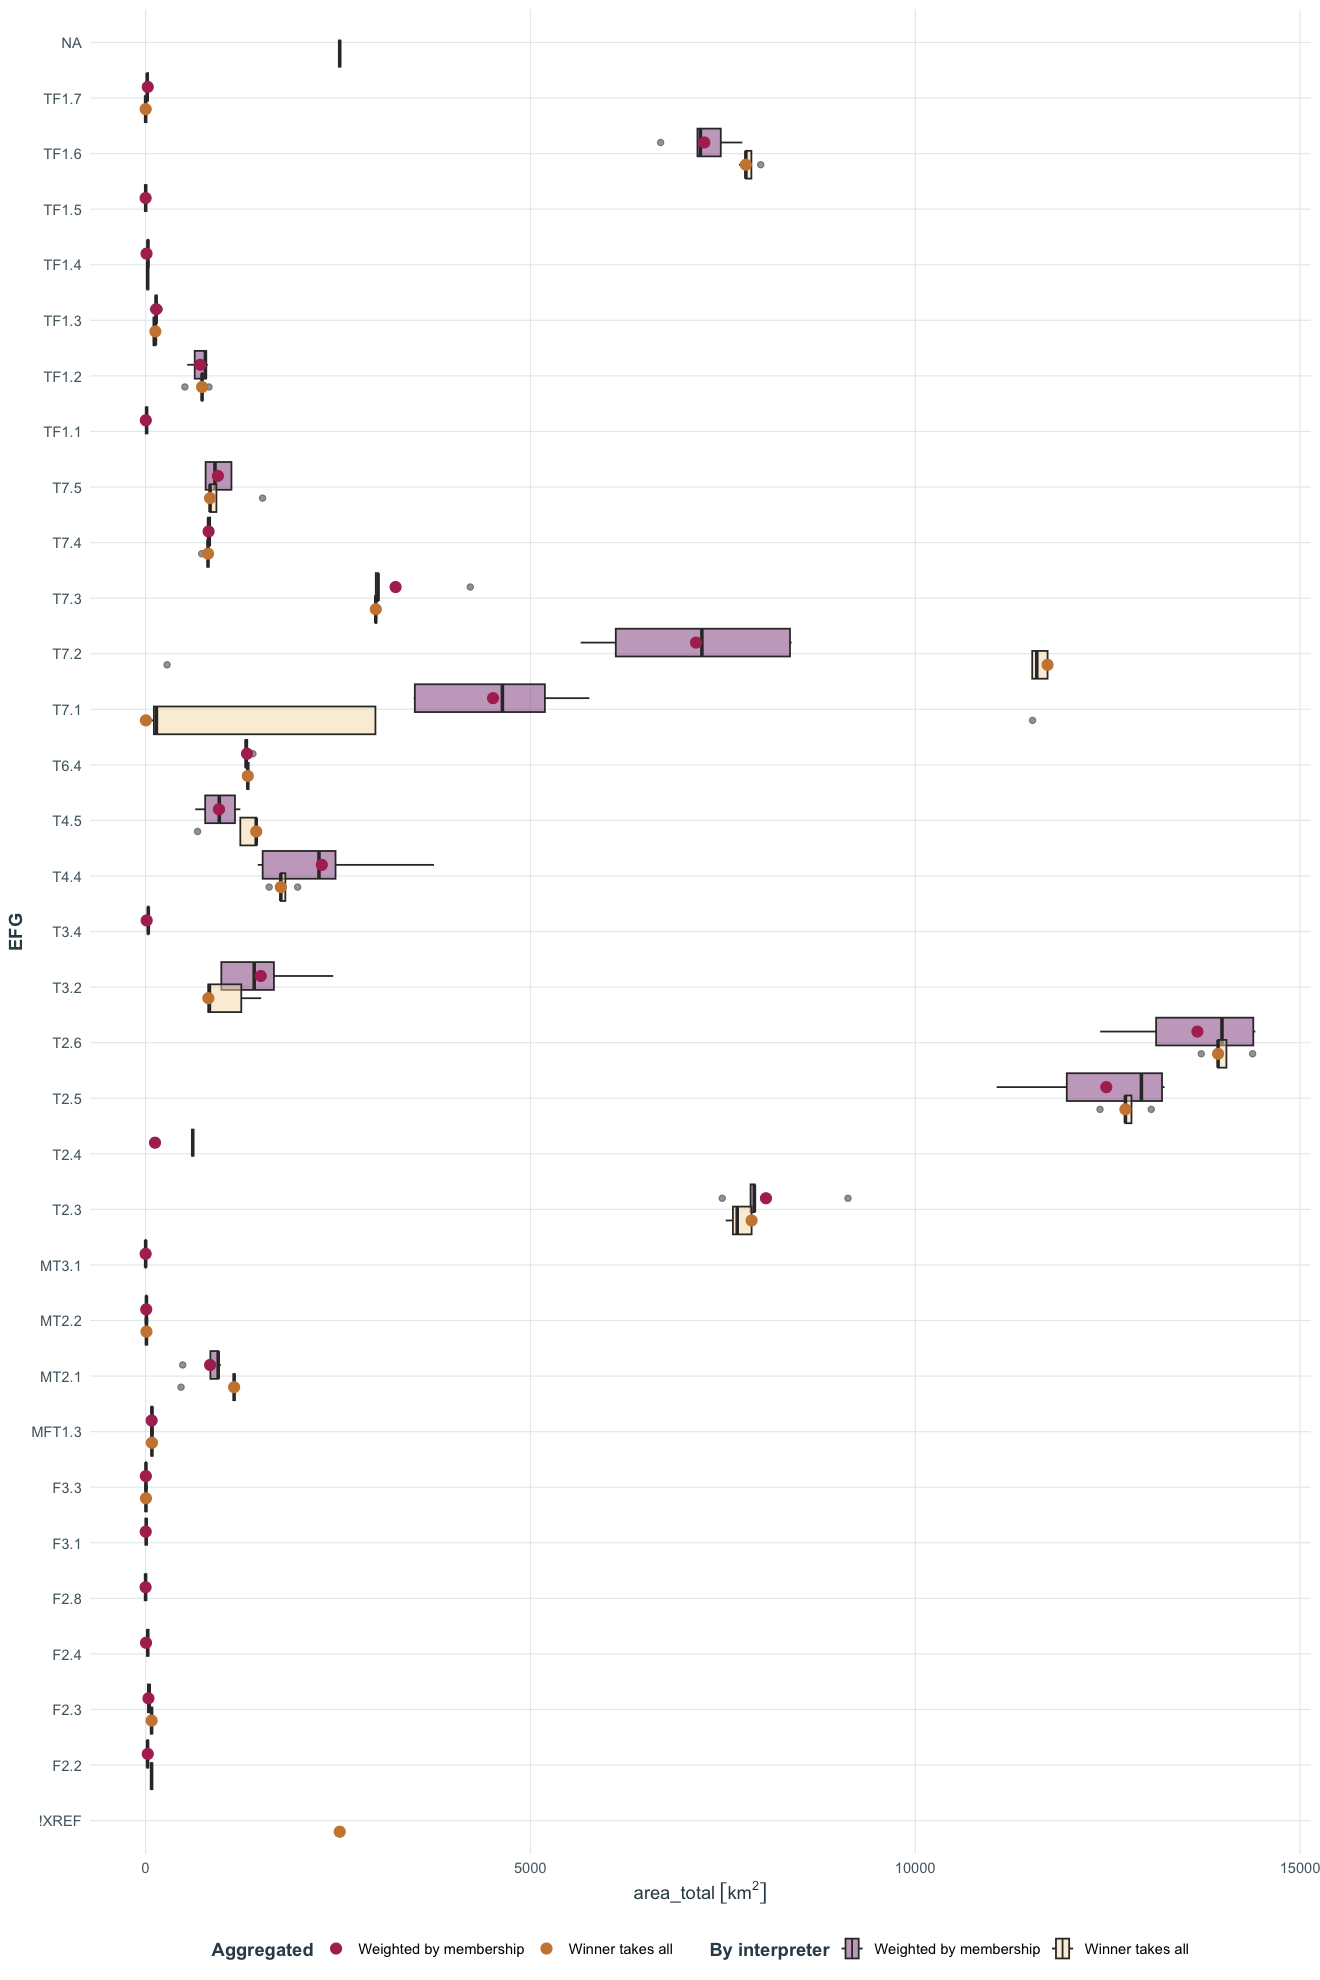

In [16]:
# Force the system device options directly in the cell
options(repr.plot.width = 12, repr.plot.height = 18)
ggplot() +
  geom_boxplot(data=EFG_memb_exp_areas, 
    aes(y=EFG, x=area_total, fill="Weighted by membership"), 
    width = .5, position=position_nudge(y=.2),
    alpha = .5) +
  geom_boxplot(data=EFG_mode_exp_areas, 
    aes(y=EFG, x=area_total, fill="Winner takes all"), 
    width = .5, position=position_nudge(y=-.2),
    alpha = .5) +
  geom_point(data=EFG_memb_agg_areas, 
    aes(y=EFG, x=area_total, col="Weighted by membership"), 
    cex=3, position=position_nudge(y=.2)) +
  geom_point(data=EFG_mode_agg_areas, 
    aes(y=EFG, x=area_total, col="Winner takes all"), 
    cex=3, position=position_nudge(y=-.2)) +
  scale_fill_manual(
    values = c("Winner takes all" = "wheat", "Weighted by membership"= "orchid4"), 
    name = "By interpreter") +
  scale_colour_manual(
    values = c("Winner takes all" = "peru", "Weighted by membership"= "maroon"), 
    name = "Aggregated") +
  theme_wp3()